# Clasificador de especies de pingüinos con Flask

**Objetivo.** Predecir la especie de un pingüino (Adelie, Chinstrap o Gentoo) a partir de la isla, cuatro medidas corporales y el sexo, y poner el modelo en una aplicación web hecha con Flask y desplegada en Render.

**Datos.** Palmer Penguins (Gorman, Williams y Fraser, 2014), observaciones de la Estación Palmer, Antártida. Se usa la copia del repositorio `seaborn-data`, guardada en `data/raw/penguins.csv` (344 filas).

**Método.** Partición estratificada con semilla 42, preprocesado y modelo dentro de un `Pipeline`, selección con validación cruzada solo sobre el entrenamiento y evaluación final en la prueba, que se usa una sola vez.

## Bloque 1: cargar y mirar los datos

In [1]:
import pandas as pd, numpy as np
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
df = pd.read_csv(RAIZ / "data" / "raw" / "penguins.csv")

print("Forma:", df.shape)
print(df.dtypes)
print("\nNulos por columna:\n", df.isna().sum())
print("\nFilas duplicadas exactas:", df.duplicated().sum())
print("\nProporción por especie:\n", df["species"].value_counts(normalize=True).round(3))
df.head()

Forma: (344, 7)
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object

Nulos por columna:
 species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Filas duplicadas exactas: 0

Proporción por especie:
 species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


### Conclusiones del Bloque 1

- El archivo tiene 344 filas y 7 columnas: especie, isla y sexo son texto, y las cuatro medidas (largo y ancho del pico, largo de la aleta y masa corporal) son decimales. No hay filas duplicadas.
- Hay 2 nulos en cada medida y 11 en el sexo. La especie y la isla están completas.
- Las especies no están balanceadas: Adelie 44,2 %, Gentoo 36,0 % y Chinstrap 19,8 %. Un modelo que dijera siempre Adelie acertaría el 44,2 %, y esa es la línea base.
- Chinstrap tendrá pocos ejemplares en la prueba, así que su recall será ruidoso.

## Bloque 2: limpieza y partición

Reglas fijadas antes de ver ningún resultado:

- Se eliminan las filas que no tienen ninguna de las cuatro medidas, porque no hay con qué predecir.
- El sexo desconocido se conserva como categoría `unknown` en lugar de borrar esas filas. En la aplicación habrá una opción equivalente.
- La partición es estratificada por especie, 80 % entrenamiento y 20 % prueba, con semilla 42. La prueba no se toca hasta el final.

In [2]:
print(df["island"].value_counts(dropna=False))
print(df["sex"].value_counts(dropna=False))

medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
sin_medidas = df[df[medidas].isna().all(axis=1)]
print("Filas sin ninguna medida:", len(sin_medidas))
print(sin_medidas)

df = df.drop(sin_medidas.index).reset_index(drop=True)
df["sex"] = df["sex"].fillna("unknown")
print("Nulos restantes:\n", df.isna().sum())

from sklearn.model_selection import train_test_split
SEMILLA = 42
X = df.drop(columns="species")
y = df["species"]
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)
print(X_ent.shape, X_pru.shape)
print(pd.DataFrame({"entrenamiento": y_ent.value_counts(normalize=True),
                    "prueba": y_pru.value_counts(normalize=True)}).round(3))

island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64
sex
MALE      168
FEMALE    165
NaN        11
Name: count, dtype: int64
Filas sin ninguna medida: 2
    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
3    Adelie  Torgersen             NaN            NaN                NaN   
339  Gentoo     Biscoe             NaN            NaN                NaN   

     body_mass_g  sex  
3            NaN  NaN  
339          NaN  NaN  
Nulos restantes:
 species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64


(273, 6) (69, 6)
           entrenamiento  prueba
species                         
Adelie             0.443   0.435
Gentoo             0.359   0.362
Chinstrap          0.198   0.203


### Conclusiones del Bloque 2

- Había 168 pingüinos en Biscoe, 124 en Dream y 52 en Torgersen, y 11 sin sexo. Dos filas (una Adelie de Torgersen y una Gentoo de Biscoe) no tenían ninguna medida ni sexo y se eliminaron: quedan 342 filas y 9 con sexo `unknown`.
- La limpieza no dependió de ningún estadístico aprendido de los datos, así que no hay fuga de información antes de partir.
- La partición dejó 273 filas de entrenamiento y 69 de prueba, con las proporciones por especie a menos de un punto de diferencia (Chinstrap 19,8 % y 20,3 %).
- La prueba es pequeña: un error cambia la exactitud en 1,4 puntos y el recall de Chinstrap, que tendrá unos 14 ejemplares, en unos 7.

## Bloque 3: análisis exploratorio (solo entrenamiento)

Se mira cuántos pingüinos de cada especie hay en cada isla y por sexo, las medias y desviaciones por especie y tres gráficos. También se compara la correlación entre largo y ancho del pico al mirar todas las especies juntas y dentro de cada una. La prueba no se toca.

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe         34          0      98
Dream          45         54       0
Torgersen      42          0       0
species  Adelie  Chinstrap  Gentoo
sex                               
FEMALE       57         26      48
MALE         59         28      47
unknown       5          0       3
species                 Adelie  Chinstrap  Gentoo
bill_length_mm    mean    38.9       49.0    47.7
                  std      2.7        3.5     3.1
bill_depth_mm     mean    18.3       18.5    14.9
                  std      1.2        1.1     0.9
flipper_length_mm mean   190.0      196.6   216.9
                  std      6.6        7.0     6.5
body_mass_g       mean  3708.3     3761.1  5076.3
                  std    465.2      393.2   508.4
Correlación largo-ancho del pico, todos juntos: -0.23
Dentro de cada especie:
 species
Adelie       0.38
Chinstrap    0.62
Gentoo       0.69
dtype: float64


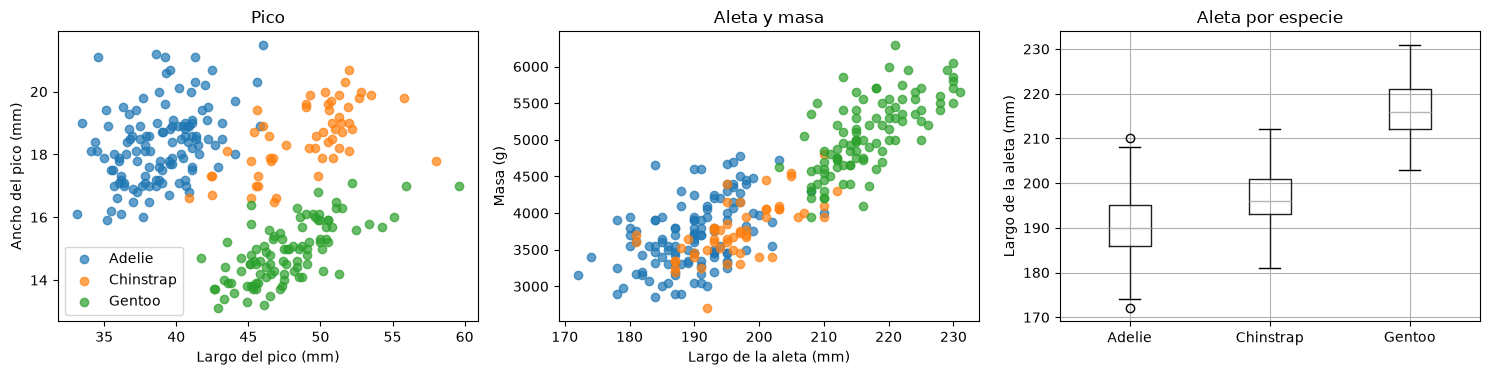

In [3]:
import matplotlib.pyplot as plt

ent = X_ent.assign(species=y_ent)
print(pd.crosstab(ent["island"], ent["species"]))
print(pd.crosstab(ent["sex"], ent["species"]))
print(ent.groupby("species")[medidas].agg(["mean", "std"]).round(1).T)

print("Correlación largo-ancho del pico, todos juntos:",
      round(ent["bill_length_mm"].corr(ent["bill_depth_mm"]), 2))
print("Dentro de cada especie:\n",
      ent.groupby("species")[["bill_length_mm", "bill_depth_mm"]].apply(lambda g: g.corr().iloc[0, 1]).round(2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for esp, g in ent.groupby("species"):
    ax[0].scatter(g["bill_length_mm"], g["bill_depth_mm"], label=esp, alpha=0.7)
    ax[1].scatter(g["flipper_length_mm"], g["body_mass_g"], label=esp, alpha=0.7)
ax[0].set(xlabel="Largo del pico (mm)", ylabel="Ancho del pico (mm)", title="Pico")
ax[1].set(xlabel="Largo de la aleta (mm)", ylabel="Masa (g)", title="Aleta y masa")
ax[0].legend()
ent.boxplot(column="flipper_length_mm", by="species", ax=ax[2])
ax[2].set(xlabel="", ylabel="Largo de la aleta (mm)", title="Aleta por especie")
plt.suptitle("")
plt.tight_layout()
plt.show()

### Conclusiones del Bloque 3

- La isla separa casi sola a dos especies: Gentoo está solo en Biscoe (98 ejemplares) y Chinstrap solo en Dream (54). Adelie aparece en las tres islas y Torgersen es todo Adelie (42). El único cruce real es Dream, con 45 Adelie y 54 Chinstrap.
- El sexo está equilibrado dentro de cada especie y la categoría `unknown` es muy pequeña (5 Adelie, 0 Chinstrap, 3 Gentoo), así que aporta poco.
- Gentoo se distingue por la aleta (216,9 mm frente a 190,0 y 196,6), la masa (5.076 g frente a unos 3.700) y el pico menos ancho (14,9 mm frente a 18,3 y 18,5). Adelie y Chinstrap se parecen en masa y ancho del pico, pero el largo del pico los separa (38,9 mm frente a 49,0 mm, con desviaciones de unos 3 mm).
- Largo y ancho del pico tienen correlación negativa al juntar las especies (-0,23) y positiva dentro de cada una (0,38 Adelie, 0,62 Chinstrap, 0,69 Gentoo): es la paradoja de Simpson. Mezclar grupos invierte la relación, y por eso conviene que el modelo vea las especies por separado.
- Limitación para la aplicación: en estos datos un pingüino de Torgersen nunca es Chinstrap ni Gentoo, y el modelo puede apoyarse demasiado en la isla. Con combinaciones que no existen en los datos sus predicciones no son fiables.

## Bloque 4: comparación de modelos (solo entrenamiento)

Reglas fijadas antes de ver resultados:

- Validación cruzada de 5 pliegues estratificada, semilla 42, sobre las 273 filas de entrenamiento.
- Métricas: exactitud y F1 macro, porque Chinstrap es la clase minoritaria.
- Gana el modelo con mejor exactitud media. Si dos quedan a menos de una desviación estándar, se elige el más simple.
- Modelos: baseline (siempre la clase más frecuente), regresión logística, KNN, árbol de decisión y bosque aleatorio.
- El preprocesado (escalado de las medidas y one-hot de `island` y `sex`) va dentro del `Pipeline`, así que no hay fuga entre pliegues y la aplicación usará el mismo pipeline.

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

def preproceso():
    return ColumnTransformer([
        ("num", StandardScaler(), medidas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["island", "sex"])])

modelos = {
    "baseline": DummyClassifier(strategy="most_frequent"),
    "regresion_logistica": LogisticRegression(max_iter=1000),
    "knn": KNeighborsClassifier(),
    "arbol": DecisionTreeClassifier(random_state=SEMILLA),
    "bosque": RandomForestClassifier(random_state=SEMILLA),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, m in modelos.items():
    r = cross_validate(Pipeline([("prep", preproceso()), ("modelo", m)]), X_ent, y_ent, cv=cv,
                       scoring=["accuracy", "f1_macro"])
    filas.append({"modelo": nombre,
                  "exactitud_media": r["test_accuracy"].mean(), "exactitud_std": r["test_accuracy"].std(),
                  "f1_macro_medio": r["test_f1_macro"].mean(), "f1_macro_std": r["test_f1_macro"].std()})
print(pd.DataFrame(filas).set_index("modelo").round(3))

                     exactitud_media  exactitud_std  f1_macro_medio  \
modelo                                                                
baseline                       0.443          0.007           0.205   
regresion_logistica            0.993          0.009           0.991   
knn                            0.985          0.014           0.983   
arbol                          0.963          0.016           0.959   
bosque                         0.989          0.009           0.987   

                     f1_macro_std  
modelo                             
baseline                    0.002  
regresion_logistica         0.011  
knn                         0.016  
arbol                       0.018  
bosque                      0.011  


### Conclusiones del Bloque 4

- El baseline (siempre Adelie) da 0,443 de exactitud y 0,205 de F1 macro en validación cruzada. Todos los modelos lo superan con mucho.
- La regresión logística tiene la mejor exactitud (0,993 ± 0,009) y F1 macro (0,991 ± 0,011), y además es la más simple.
- El bosque aleatorio (0,989) y KNN (0,985) quedan a menos de una desviación estándar de la logística. No hay evidencia de que sean peores ni mejores, y con 273 filas una diferencia de 0,004 equivale a poco más de una fila.
- El árbol de decisión (0,963 ± 0,016) queda a unos 0,03 de la logística, casi el doble de su desviación estándar. Es el único modelo claramente por debajo.
- Por la regla fijada de antemano se elige la regresión logística.

## Bloque 5: ajuste y comparación de variantes (solo entrenamiento)

Mismas reglas de validación (5 pliegues estratificados, semilla 42, prueba sin tocar):

- Se ajusta `C`, la regularización de la regresión logística, con `GridSearchCV` sobre 0,01; 0,1; 1; 10 y 100. En caso de empate gana el primero de la lista, el más regularizado.
- Se comparan dos variantes: medidas + isla + sexo frente a solo medidas. Si la segunda queda a menos de una desviación estándar de la primera, se elige la más simple, que además evita combinaciones imposibles en la aplicación.

In [5]:
from sklearn.model_selection import GridSearchCV

def pipeline(con_categoricas):
    transf = [("num", StandardScaler(), medidas)]
    if con_categoricas:
        transf.append(("cat", OneHotEncoder(handle_unknown="ignore"), ["island", "sex"]))
    return Pipeline([("prep", ColumnTransformer(transf)),
                     ("modelo", LogisticRegression(max_iter=1000))])

rejilla = {"modelo__C": [0.01, 0.1, 1, 10, 100]}
for nombre, con_cat in {"medidas + isla + sexo": True, "solo medidas": False}.items():
    gs = GridSearchCV(pipeline(con_cat), rejilla, cv=cv, scoring="accuracy")
    gs.fit(X_ent, y_ent)
    print(nombre, "| mejor C:", gs.best_params_["modelo__C"],
          "| exactitud CV:", round(gs.best_score_, 3),
          "| std:", round(gs.cv_results_["std_test_score"][gs.best_index_], 3))
    print(pd.DataFrame(gs.cv_results_)[["param_modelo__C", "mean_test_score", "std_test_score"]]
          .round(3).to_string(index=False))

medidas + isla + sexo | mejor C: 1 | exactitud CV: 0.993 | std: 0.009
 param_modelo__C  mean_test_score  std_test_score
            0.01            0.927           0.026
            0.10            0.985           0.014
            1.00            0.993           0.009
           10.00            0.993           0.015
          100.00            0.993           0.015


solo medidas | mejor C: 10 | exactitud CV: 0.982 | std: 0.016
 param_modelo__C  mean_test_score  std_test_score
            0.01            0.916           0.025
            0.10            0.974           0.015
            1.00            0.982           0.012
           10.00            0.982           0.016
          100.00            0.978           0.014


### Conclusiones del Bloque 5

- Con isla y sexo, `C` = 1, 10 y 100 empatan en 0,993 de exactitud en validación cruzada. Por la regla del empate se elige `C` = 1, el más regularizado. Con `C` = 0,01 ambas variantes caen mucho (0,927 y 0,916), porque el modelo se queda corto.
- La mejor variante de solo medidas llega a 0,982, es decir 0,011 menos que la completa (unas 3 filas de 273).
- Esa diferencia es algo mayor que la desviación estándar de la variante completa (0,009), aunque menor que la suya propia (0,016). Es un caso en el borde; aplicando la regla literal, solo medidas no queda dentro y se mantiene la variante completa.
- La aplicación incluirá isla y sexo (con la opción "No sé"), y la limitación de las combinaciones imposibles, como Torgersen con medidas de Gentoo, se documenta en el README.

## Bloque 6: evaluación final en la prueba (una sola vez)

Se ajusta el pipeline elegido (regresión logística, `C` = 1, medidas + isla + sexo) sobre las 273 filas de entrenamiento, no sobre todo el conjunto, para que la nota de la prueba sea válida. Se compara con el baseline, se muestran el informe por clase, la matriz de confusión y los errores concretos, y se guarda el modelo con la semilla en el nombre. Después se recarga el archivo y se comprueba que da las mismas predicciones.

In [6]:
import joblib
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

final = pipeline(True).set_params(modelo__C=1)
final.fit(X_ent, y_ent)
pred = final.predict(X_pru)
print("Exactitud en prueba:", round(accuracy_score(y_pru, pred), 3),
      "| F1 macro:", round(f1_score(y_pru, pred, average="macro"), 3))
base = DummyClassifier(strategy="most_frequent").fit(X_ent, y_ent)
print("Baseline en prueba:", round(accuracy_score(y_pru, base.predict(X_pru)), 3))
print(classification_report(y_pru, pred, digits=3))
print(pd.DataFrame(confusion_matrix(y_pru, pred, labels=final.classes_),
                   index=final.classes_, columns=final.classes_))
mal = pred != y_pru
print("Errores:", int(mal.sum()))
print(X_pru[mal].assign(real=y_pru[mal], predicho=pred[mal]))

(RAIZ / "models").mkdir(exist_ok=True)
ruta_modelo = RAIZ / "models" / "logistic_regression_seed42.pkl"
joblib.dump(final, ruta_modelo)
recargado = joblib.load(ruta_modelo)
print("Recarga idéntica:", bool((recargado.predict(X_pru) == pred).all()))

Exactitud en prueba: 1.0 | F1 macro: 1.0
Baseline en prueba: 0.435
              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        30
   Chinstrap      1.000     1.000     1.000        14
      Gentoo      1.000     1.000     1.000        25

    accuracy                          1.000        69
   macro avg      1.000     1.000     1.000        69
weighted avg      1.000     1.000     1.000        69

           Adelie  Chinstrap  Gentoo
Adelie         30          0       0
Chinstrap       0         14       0
Gentoo          0          0      25
Errores: 0
Empty DataFrame
Columns: [island, bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g, sex, real, predicho]
Index: []
Recarga idéntica: True


### Conclusiones del Bloque 6

- La regresión logística (`C` = 1, medidas + isla + sexo) acertó los 69 pingüinos de la prueba: exactitud 1,000 y F1 macro 1,000, frente a 0,435 del baseline. Por clase, Adelie 30/30, Chinstrap 14/14 y Gentoo 25/25, sin ningún error.
- Un 100 % sobre 69 filas no significa que el modelo sea perfecto: con cero errores en 69, solo se puede decir que la tasa de error real probablemente es baja, con un techo plausible de unos 4 puntos. La estimación más informativa es la de validación cruzada (0,993 ± 0,009), que implica un error ocasional.
- Ambas cifras coinciden y no se ajustó nada después de ver la prueba, que es lo que da valor al resultado.
- Limitaciones: los datos son de tres islas concretas (342 pingüinos) y el modelo no conoce combinaciones imposibles, como Torgersen con medidas de Gentoo.
- El modelo se guardó en `models/logistic_regression_seed42.pkl` y la recarga da las mismas predicciones.